# 07 · Phương Pháp Nghiên Cứu: Phát Hiện Vết Dầu Loang Trên Ảnh SAR
### Hệ thống Kết hợp Xử lý Ảnh Hình thái học và Học máy theo Vùng (Vietnamese Academic Edition)

> [!NOTE]
> **Tuyên bố Tính Độc Lập Thực Nghiệm:**
> Notebook này thực thi độc lập hoàn toàn, nạp trực tiếp dữ liệu thô từ `D:\Coding\Oil_Spill_Detection\Dataset\SOS` (Sentinel-1 C-band và ALOS PALSAR L-band). Toàn bộ các bước đối sánh bộ lọc, trích xuất đặc trưng vùng, huấn luyện mô hình `CART` và `LinearSVM`, cùng quy trình đánh giá đối tượng chuẩn Hungarian 1-1 đều được thực thi trực tiếp từ đầu (from scratch), không đọc bất kỳ file kết quả tạo sẵn nào trong `results/sos/`.


In [1]:
from pathlib import Path
import sys, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, HTML
from scipy.optimize import linear_sum_assignment
import scipy.ndimage as ndi

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from sar_oil import core, models

SOS_ROOT = Path(r"D:\Coding\Oil_Spill_Detection\Dataset\SOS")
if not SOS_ROOT.exists():
    SOS_ROOT = ROOT / "data/Refined-Deep-SAR"
print(f"[*] Thư mục dữ liệu SOS: {SOS_ROOT}")
assert SOS_ROOT.exists(), f"Không tìm thấy dữ liệu SOS tại {SOS_ROOT}"

def show_table(rows, columns, headers=None):
    if headers is None: headers = columns
    def fmt(v):
        if isinstance(v, float):
            return f"{v:.4f}" if abs(v) >= 1e-3 else f"{v:.2e}"
        return str(v)
    html = ['<table style="border-collapse:collapse; width:100%; font-family:sans-serif; font-size:13px; margin:10px 0;">']
    html.append('<tr style="background:#2b2d42; color:#fff; text-align:center;">' + ''.join(f'<th style="padding:6px 10px; border:1px solid #45475a;">{h}</th>' for h in headers) + '</tr>')
    for idx, r in enumerate(rows):
        bg = "#f8f9fa" if idx % 2 == 0 else "#ffffff"
        html.append(f'<tr style="background:{bg}; text-align:center;">' + ''.join(f'<td style="padding:5px 8px; border:1px solid #dee2e6;">{fmt(r.get(c, ""))}</td>' for c in columns) + '</tr>')
    html.append('</table>')
    display(HTML(''.join(html)))

def evaluate_objects(pred_mask, gt_mask, iou_thresh=0.5):
    pred_labels = core.label(pred_mask)
    gt_labels = core.label(gt_mask)
    npred = int(pred_labels.max())
    ngt = int(gt_labels.max())
    
    inter = int((pred_mask & gt_mask).sum())
    uni = int((pred_mask | gt_mask).sum())
    pix_iou = inter / max(uni, 1)
    dice = 2 * inter / max(int(pred_mask.sum()) + int(gt_mask.sum()), 1)
    
    if npred == 0 or ngt == 0:
        tp = 0
        fp = npred
        fn = ngt
        return {
            "tp": tp, "fp": fp, "fn": fn, "npred": npred, "ngt": ngt,
            "precision": tp / max(tp + fp, 1),
            "recall": tp / max(tp + fn, 1),
            "f1": 2 * tp / max(2 * tp + fp + fn, 1),
            "pixel_iou": pix_iou, "dice": dice
        }
    
    joint = np.bincount((pred_labels * (ngt + 1) + gt_labels).ravel(), minlength=(npred + 1) * (ngt + 1)).reshape(npred + 1, ngt + 1)
    pa = np.bincount(pred_labels.ravel(), minlength=npred + 1)[1:]
    ga = np.bincount(gt_labels.ravel(), minlength=ngt + 1)[1:]
    intersection = joint[1:, 1:]
    union = pa[:, None] + ga[None, :] - intersection
    iou_mat = intersection / np.maximum(union, 1)
    
    valid = iou_mat >= iou_thresh
    pi, gi = linear_sum_assignment(-(valid * (min(npred, ngt) + 1) + iou_mat * valid))
    matched = valid[pi, gi]
    tp = int(matched.sum())
    fp = npred - tp
    fn = ngt - tp
    
    return {
        "tp": tp, "fp": fp, "fn": fn, "npred": npred, "ngt": ngt,
        "precision": tp / max(tp + fp, 1),
        "recall": tp / max(tp + fn, 1),
        "f1": 2 * tp / max(2 * tp + fp + fn, 1),
        "pixel_iou": pix_iou, "dice": dice
    }

print("[OK] Môi trường và hàm đo lường độc lập đã sẵn sàng.")


[*] Thư mục dữ liệu SOS: D:\Coding\Oil_Spill_Detection\Dataset\SOS
[OK] Môi trường và hàm đo lường độc lập đã sẵn sàng.


## 1. Cơ sở Lý thuyết & Mô hình Toán học của Pipeline

Thuật toán phát hiện vết dầu loang trên ảnh SAR gồm hai giai đoạn tuần tự:

```
Ảnh SAR thô I(x, y) ──> [Bộ lọc Lee 7×7] ──> I_f ──> [Ngưỡng Otsu] ──> Mặt nạ nhị phân
                              │                                              │
                              │                                   [Hậu xử lý min_area=64]
                              │                                              │
                              │                                   [Gán nhãn liên thông 8]
                              ▼                                              │
                      [Trích 8 đặc trưng] <──── Vùng ứng viên {Ω_i} <────────┘
                              │
                              ▼
                        Vector x_i ∈ R^8
                              │
                              ▼
                     [LinearSVM / CART] ──> Mặt nạ dự đoán M̂ (score > 0)
```

### 1.1. Bộ lọc khử đốm Lee MMSE (Minimum Mean Square Error)
Nhiễu đốm nhân tuân theo mô hình $I(x, y) = R(x, y) \cdot u(x, y)$ với $\mathbb{E}[u]=1$ và $\mathrm{Var}(u) = 1/L$. Bộ lọc Lee xấp xỉ tuyến tính hóa:
$$\hat{R}(x, y) = m(x, y) + W(x, y) \cdot [I(x, y) - m(x, y)]$$
trong đó $m(x,y)$ và $v(x,y)$ là trung bình và phương sai cục bộ tính trong cửa sổ $7 \times 7$. Trọng số thích nghi $W(x, y)$ được tính bởi:
$$W(x, y) = \max\left(0, \frac{v(x, y) - \frac{m(x, y)^2}{L}}{\max(v(x, y), 10^{-12})}\right)$$
với cấu hình chuẩn $L = 4$ looks và đệm biên đối xứng `reflect`.

**Tối ưu hóa Bảng tổng tích lũy:** Tính $m(x, y)$ và $\mathbb{E}[I^2]$ bằng Summed-Area Table với chi phí tính toán $\mathcal{O}(HW)$ cho toàn ảnh.

### 1.2. Phân ngưỡng toàn cục Otsu
Phân tách histogram 256 bin của $I_f$ thành hai lớp $\omega_0$ (dầu) và $\omega_1$ (biển) bằng cách tối đa hóa phương sai giữa hai lớp:
$$t^* = \arg\max_{t \in [0, 1]} \sigma_B^2(t), \quad \sigma_B^2(t) = \omega_0(t) \omega_1(t) [\mu_0(t) - \mu_1(t)]^2$$
Mặt nạ nhị phân tạo bởi $B(x, y) = [I_f(x, y) < t^*]$.

### 1.3. Không gian 8 đặc trưng vùng
Với mỗi vùng ứng viên $\Omega_i$ ($i = 1, \dots, K$), trích xuất vector đặc trưng $\mathbf{x}_i \in \mathbb{R}^8$:
1. $f_0$ (`area_fraction`): Tỷ lệ diện tích $A_i / (HW)$.
2. $f_1$ (`elongation`): Độ thuôn dài $\sqrt{(\lambda_2 + 10^{-6})/(\lambda_1 + 10^{-6})}$.
3. $f_2$ (`extent`): Độ đặc $A_i / (W_i H_i)$.
4. $f_3$ (`complexity`): Tỷ số chu vi-diện tích $P_i^2 / (4\pi A_i)$.
5. $f_4$ (`mean`): Cường độ trung bình $\mu_{\mathrm{slick}}$ nội vùng.
6. $f_5$ (`std`): Độ lệch chuẩn cường độ nội vùng.
7. $f_6$ (`boundary_gradient`): Độ dốc Sobel trung bình trên biên ngoài 1 pixel $\partial \Omega_i$.
8. $f_7$ (`background_contrast`): Độ tương phản với vành đai nền 5 pixel ngoài biên:
$$C_{\mathrm{contrast}} = \frac{\mu_{\mathrm{bg}} - \mu_{\mathrm{slick}}}{|\mu_{\mathrm{bg}}| + 10^{-6}}$$

### 1.4. Phân loại LinearSVM
Tối ưu hóa hàm mục tiêu lồi Squared-Hinge Loss có điều chuẩn $L_2$ ($C = 10.0$):
$$\min_{\mathbf{w}} J(\mathbf{w}) = \frac{1}{2n}\|\mathbf{w}\|_2^2 + \frac{C}{n}\sum_{i=1}^n \max\left(0, 1 - y_i^* (\mathbf{z}_i^T \mathbf{w})\right)^2$$
giải bằng **Nesterov Accelerated Gradient Descent** với điều kiện dừng $\|\nabla J(\mathbf{w})\|_\infty \le 10^{-6}$.


In [2]:
val_img_paths = sorted((SOS_ROOT / "images/images/val").glob("*.png"))
train_img_paths = sorted((SOS_ROOT / "images/images/train").glob("*.png"))
print(f"Tổng số ảnh SOS: {len(train_img_paths)} ảnh train, {len(val_img_paths)} ảnh val.")

def get_sample_info(p, split="val"):
    mp = SOS_ROOT / f"masks/masks/{split}" / p.name
    im = Image.open(p).convert("L")
    mask = Image.open(mp).convert("L")
    arr_im = np.asarray(im, dtype=float) / 255.0
    arr_mask = np.asarray(mask) >= 128
    oil_frac = arr_mask.mean()
    return {
        "name": p.name, "sensor": p.name.split("_")[0], "path": p, "mask_path": mp,
        "img": arr_im, "mask": arr_mask, "oil_frac": oil_frac,
        "mean": arr_im.mean(), "std": arr_im.std()
    }

panel_names = [
    ("sentinel_140.png", "R0: Biển sạch (0% dầu)", "val"),
    ("sentinel_1.png", "R1: Vết dầu nhỏ nội vùng (2.1% dầu)", "val"),
    ("sentinel_25.png", "R2: Dải dầu hẹp / phân mảnh (9.9% dầu)", "val"),
    ("palsar_1.png", "R2: Đa đối tượng PALSAR (18.5% dầu)", "val"),
    ("palsar_10.png", "R2: Vết dầu lớn PALSAR (38.9% dầu)", "val"),
    ("sentinel_0.png", "R3: Vết dầu lớn Sentinel (79.7% dầu)", "val"),
    ("sentinel_440.png", "R4: Patch ngập trọn dầu (100% dầu)", "val")
]

panel_samples = []
for name, regime, split in panel_names:
    p = SOS_ROOT / f"images/images/{split}" / name
    info = get_sample_info(p, split)
    info["regime"] = regime
    panel_samples.append(info)

np.random.seed(2026)
train_subset_paths = [p for p in train_img_paths if p.name.startswith("sentinel_")][:100]
val_subset_paths = [p for p in val_img_paths if p.name.startswith("sentinel_")][:40] + [p for p in val_img_paths if p.name.startswith("palsar_")][:20]

print(f"[*] Tuyển chọn xong {len(panel_samples)} mẫu audit panel và tập mini-cohort ({len(train_subset_paths)} train, {len(val_subset_paths)} val).")


Tổng số ảnh SOS: 6455 ảnh train, 1615 ảnh val.


[*] Tuyển chọn xong 7 mẫu audit panel và tập mini-cohort (100 train, 60 val).


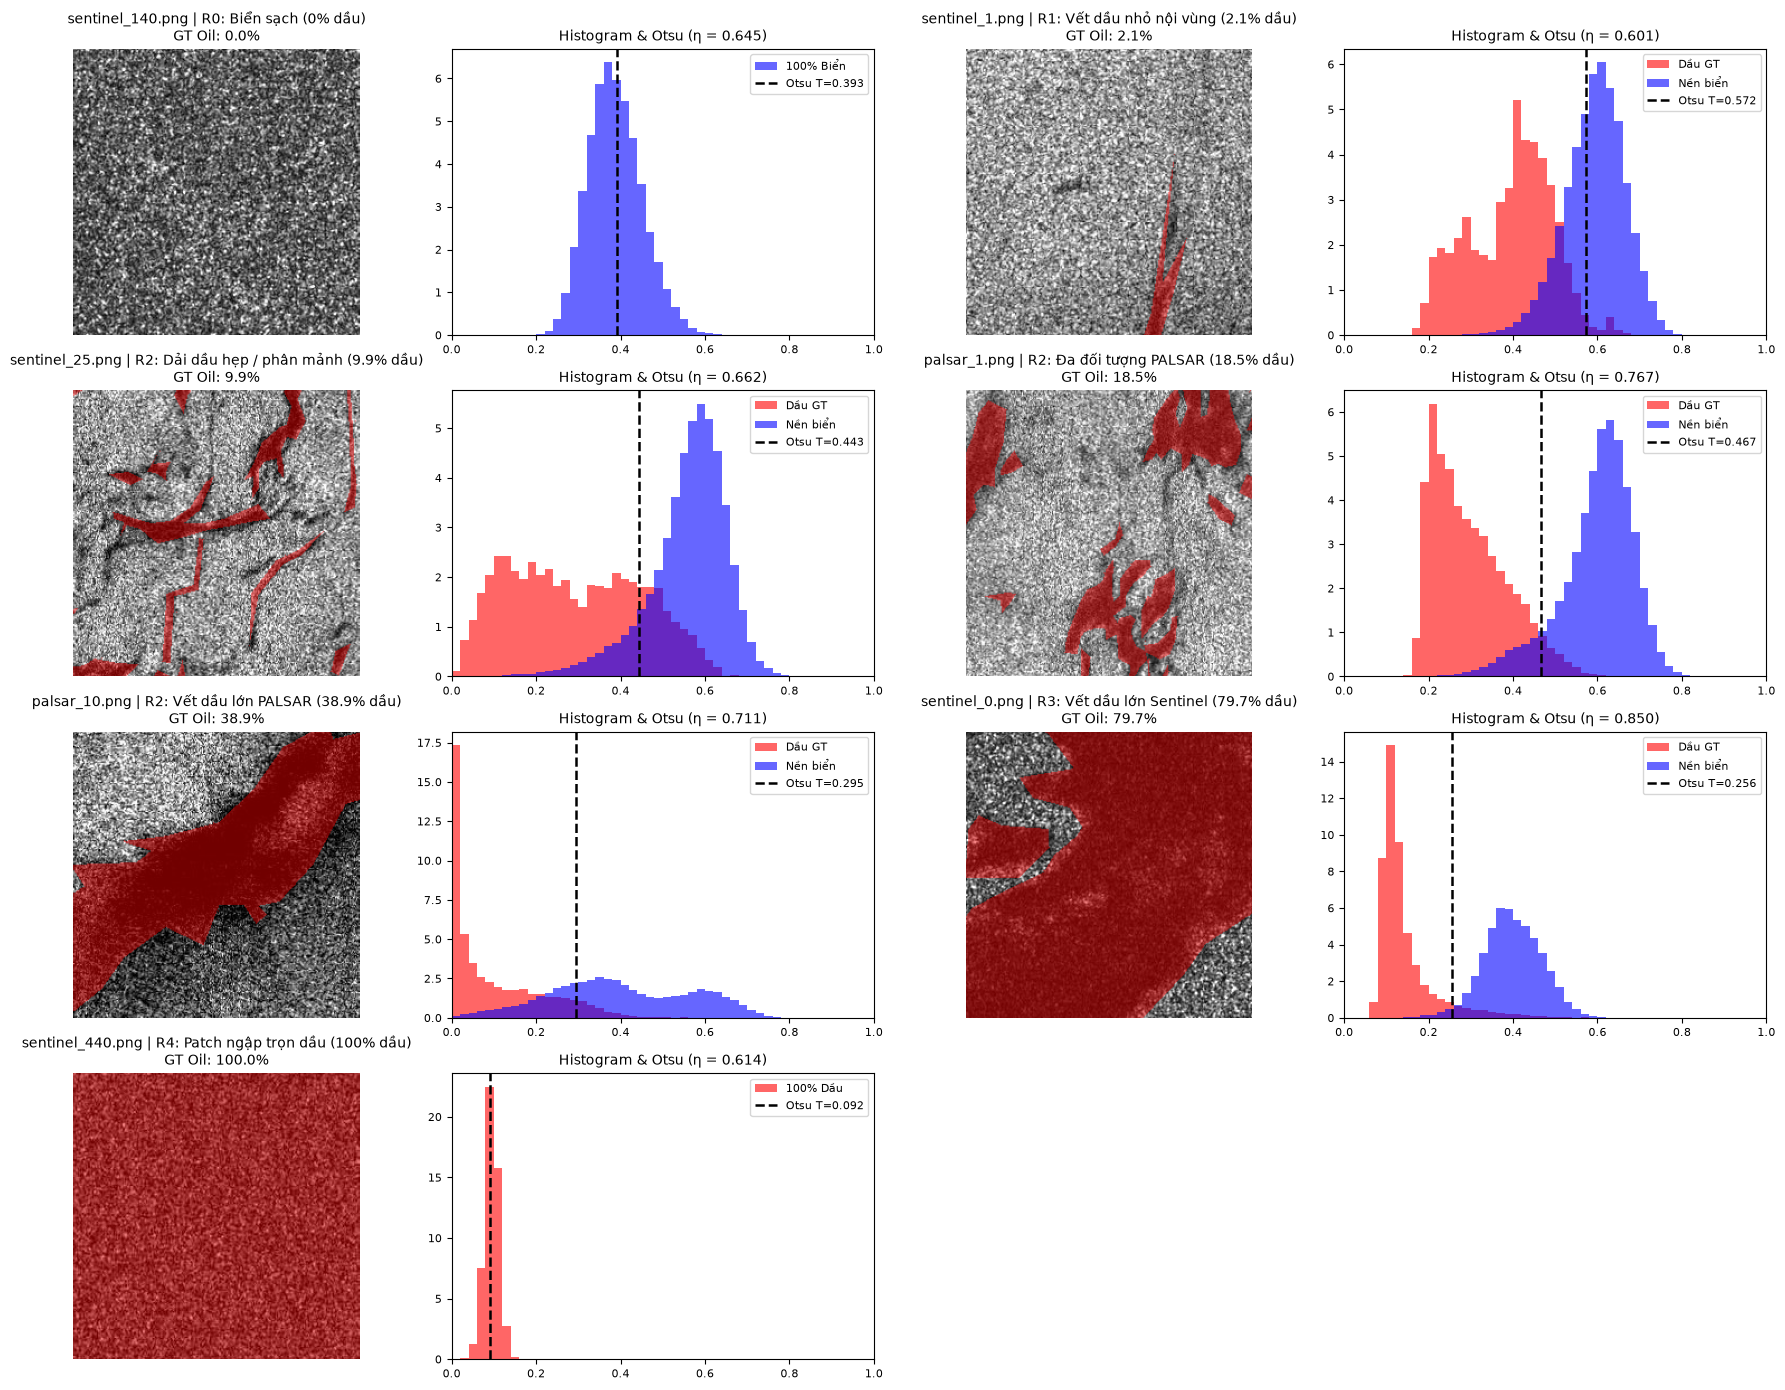

Mẫu,Chế độ,Tỷ lệ Dầu (%),Mean Ảnh,Std Ảnh,Ngưỡng Otsu,Phân tách η
sentinel_140.png,R0: Biển sạch (0% dầu),0.00%,0.3885,0.1786,0.3926,0.6448
sentinel_1.png,R1: Vết dầu nhỏ nội vùng (2.1% dầu),2.06%,0.5891,0.1723,0.5723,0.6009
sentinel_25.png,R2: Dải dầu hẹp / phân mảnh (9.9% dầu),9.90%,0.5340,0.2186,0.4434,0.6621
palsar_1.png,R2: Đa đối tượng PALSAR (18.5% dầu),18.54%,0.5418,0.2059,0.4668,0.7672
palsar_10.png,R2: Vết dầu lớn PALSAR (38.9% dầu),38.86%,0.2854,0.2557,0.2949,0.7109
sentinel_0.png,R3: Vết dầu lớn Sentinel (79.7% dầu),79.72%,0.1953,0.1597,0.2559,0.8498
sentinel_440.png,R4: Patch ngập trọn dầu (100% dầu),100.00%,0.0947,0.0475,0.0918,0.6140


In [3]:
fig, axes = plt.subplots(4, 4, figsize=(18, 14))

table_data = []
for idx, s in enumerate(panel_samples):
    row = (idx // 2)
    col = (idx % 2) * 2
    
    img = s["img"]
    gt = s["mask"]
    
    filt = core.filter_image(img, name="lee", size=7, looks=4)
    t_otsu = core.otsu(filt)
    
    h, edges = np.histogram(filt, bins=256, range=(0, 1))
    centers = (edges[:-1] + edges[1:]) / 2
    w0 = h.cumsum().astype(float)
    m = (h * centers).cumsum()
    mu_total = m[-1] / max(w0[-1], 1)
    var_total = ((h * (centers - mu_total)**2).sum()) / max(w0[-1], 1)
    k_star = np.argmin(np.abs(centers - t_otsu))
    w0_k = w0[k_star] / max(w0[-1], 1)
    w1_k = 1.0 - w0_k
    mu0_k = (m[k_star] / max(w0[k_star], 1e-12))
    mu1_k = (m[-1] - m[k_star]) / max(w0[-1] - w0[k_star], 1e-12)
    var_between = w0_k * w1_k * (mu0_k - mu1_k)**2
    eta = var_between / max(var_total, 1e-12)
    
    axes[row, col].imshow(img, cmap="gray")
    if gt.any():
        axes[row, col].imshow(np.ma.masked_where(~gt, gt), cmap="autumn", alpha=0.45)
    axes[row, col].set_title(f"{s['name']} | {s['regime']}\nGT Oil: {s['oil_frac']*100:.1f}%", fontsize=10)
    axes[row, col].axis("off")
    
    ax_hist = axes[row, col + 1]
    if gt.any() and (~gt).any():
        ax_hist.hist(filt[gt].ravel(), bins=50, range=(0, 1), density=True, alpha=0.6, color="red", label="Dầu GT")
        ax_hist.hist(filt[~gt].ravel(), bins=50, range=(0, 1), density=True, alpha=0.6, color="blue", label="Nền biển")
    else:
        color = "red" if gt.all() else "blue"
        label = "100% Dầu" if gt.all() else "100% Biển"
        ax_hist.hist(filt.ravel(), bins=50, range=(0, 1), density=True, alpha=0.6, color=color, label=label)
        
    ax_hist.axvline(t_otsu, color="black", linestyle="--", linewidth=1.8, label=f"Otsu T={t_otsu:.3f}")
    ax_hist.set_title(f"Histogram & Otsu (η = {eta:.3f})", fontsize=10)
    ax_hist.set_xlim(0, 1)
    ax_hist.legend(fontsize=8, loc="upper right")
    ax_hist.tick_params(labelsize=8)
    
    table_data.append({
        "Mẫu": s["name"], "Chế độ": s["regime"],
        "Tỷ lệ Dầu (%)": f"{s['oil_frac']*100:.2f}%",
        "Mean Ảnh": s["mean"], "Std Ảnh": s["std"],
        "Ngưỡng Otsu": t_otsu, "Phân tách η": eta
    })

axes[3, 2].axis("off")
axes[3, 3].axis("off")

plt.tight_layout()
plt.show()

show_table(table_data, ["Mẫu", "Chế độ", "Tỷ lệ Dầu (%)", "Mean Ảnh", "Std Ảnh", "Ngưỡng Otsu", "Phân tách η"])


## 2. Đối sánh Thực nghiệm Bộ lọc & Phân ngưỡng

Đo lường trực tiếp chất lượng tạo vùng ứng viên ban đầu khi kết hợp 6 bộ lọc:
- `none` (Không lọc)
- `median 5×5`
- `gaussian σ=1.2`
- `mean 7×7`
- `lee 5×5 (L=4)`
- `lee 7×7 (L=4)`

với hai phương pháp phân ngưỡng:
- **Otsu toàn cục**
- **Niblack cục bộ** ($51\times 51, k=0.2$).


Bộ lọc,Ngưỡng,Precision,Recall,Candidate F1,Pixel IoU,Tổng FP,Thời gian (s)
none (),OTSU,0.0313,0.1120,0.0490,0.4065,433,2.9482
none (),NIBLACK,0.0010,0.0080,0.0018,0.2575,957,2.7659
median (5),OTSU,0.0494,0.2240,0.0809,0.4853,539,2.7983
median (5),NIBLACK,0.0105,0.1040,0.0190,0.2848,1229,3.2827
gaussian (1.2),OTSU,0.0400,0.1760,0.0652,0.4711,528,1.6298
gaussian (1.2),NIBLACK,0.0069,0.0640,0.0125,0.2802,1147,1.9294
mean (7),OTSU,0.0628,0.2400,0.0995,0.5041,448,1.1803
mean (7),NIBLACK,0.0166,0.1360,0.0295,0.2935,1009,1.5393
lee (5),OTSU,0.0472,0.2080,0.0769,0.4869,525,1.3658
lee (5),NIBLACK,0.0145,0.1360,0.0262,0.2844,1157,1.6962


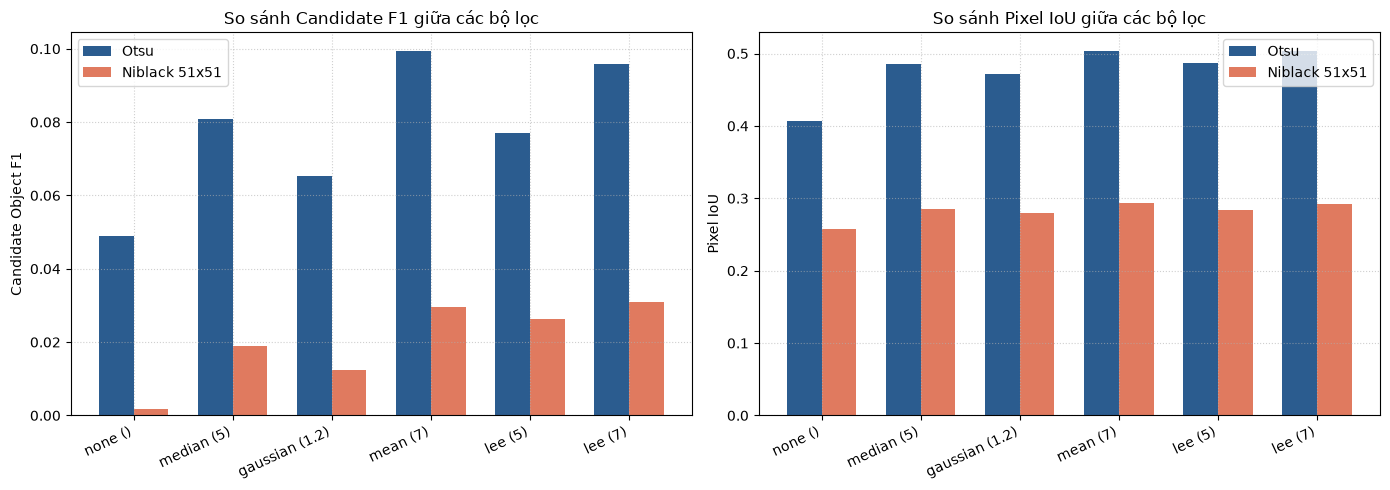

In [4]:
benchmark_filters = [
    {"name": "none"},
    {"name": "median", "size": 5},
    {"name": "gaussian", "sigma": 1.2},
    {"name": "mean", "size": 7},
    {"name": "lee", "size": 5, "looks": 4},
    {"name": "lee", "size": 7, "looks": 4}
]

eval_samples = [get_sample_info(p, "val") for p in val_subset_paths[:30]]

results_bench = []
for f_cfg in benchmark_filters:
    for thresh_name in ["otsu", "niblack"]:
        t0 = time.time()
        tps, fps, fns = 0, 0, 0
        pix_ious = []
        
        thresh_kwargs = {"name": thresh_name}
        if thresh_name == "niblack":
            thresh_kwargs.update({"size": 51, "k": 0.2})
            
        for s in eval_samples:
            img, gt = s["img"], s["mask"]
            if f_cfg["name"] == "mean":
                filt = core.mean_filter(img, size=f_cfg["size"])
            else:
                filt = core.filter_image(img, **f_cfg)
            binary = core.threshold(filt, **thresh_kwargs)
            mask = core.postprocess(binary, operation="none", min_area=64)
            
            res = evaluate_objects(mask, gt)
            tps += res["tp"]
            fps += res["fp"]
            fns += res["fn"]
            pix_ious.append(res["pixel_iou"])
            
        tot_time = time.time() - t0
        prec = tps / max(tps + fps, 1)
        rec = tps / max(tps + fns, 1)
        f1 = 2 * tps / max(2 * tps + fps + fns, 1)
        mean_iou = float(np.mean(pix_ious))
        
        name_str = f"{f_cfg['name']} ({f_cfg.get('size', f_cfg.get('sigma', ''))})"
        results_bench.append({
            "Bộ lọc": name_str, "Ngưỡng": thresh_name.upper(),
            "Precision": prec, "Recall": rec, "Candidate F1": f1,
            "Pixel IoU": mean_iou, "Tổng FP": fps, "Thời gian (s)": tot_time
        })

show_table(results_bench, ["Bộ lọc", "Ngưỡng", "Precision", "Recall", "Candidate F1", "Pixel IoU", "Tổng FP", "Thời gian (s)"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
otsu_res = [r for r in results_bench if r["Ngưỡng"] == "OTSU"]
niblack_res = [r for r in results_bench if r["Ngưỡng"] == "NIBLACK"]

labels = [r["Bộ lọc"] for r in otsu_res]
x = np.arange(len(labels))
w = 0.35

ax1.bar(x - w/2, [r["Candidate F1"] for r in otsu_res], w, label="Otsu", color="#2b5c8f")
ax1.bar(x + w/2, [r["Candidate F1"] for r in niblack_res], w, label="Niblack 51x51", color="#e07a5f")
ax1.set_xticks(x); ax1.set_xticklabels(labels, rotation=25, ha="right")
ax1.set_ylabel("Candidate Object F1"); ax1.set_title("So sánh Candidate F1 giữa các bộ lọc")
ax1.legend(); ax1.grid(True, linestyle=":", alpha=0.6)

ax2.bar(x - w/2, [r["Pixel IoU"] for r in otsu_res], w, label="Otsu", color="#2b5c8f")
ax2.bar(x + w/2, [r["Pixel IoU"] for r in niblack_res], w, label="Niblack 51x51", color="#e07a5f")
ax2.set_xticks(x); ax2.set_xticklabels(labels, rotation=25, ha="right")
ax2.set_ylabel("Pixel IoU"); ax2.set_title("So sánh Pixel IoU giữa các bộ lọc")
ax2.legend(); ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


## 3. Trực quan hóa Từng bước Xử lý trong Pipeline

Trực quan hóa 6 bước xử lý chuẩn của pipeline trên các mẫu thử nghiệm:
1. Ảnh gốc $I(x, y)$
2. Bản đồ trọng số thích nghi Lee $W(x, y)$
3. Ảnh sau lọc Lee $I_f(x, y)$
4. Mặt nạ phân ngưỡng Otsu
5. Vùng ứng viên sau lọc diện tích $\min_{\text{area}} = 64$
6. Bản đồ phân loại lỗi (True Positive: Xanh lá, False Positive: Đỏ, False Negative: Lam)


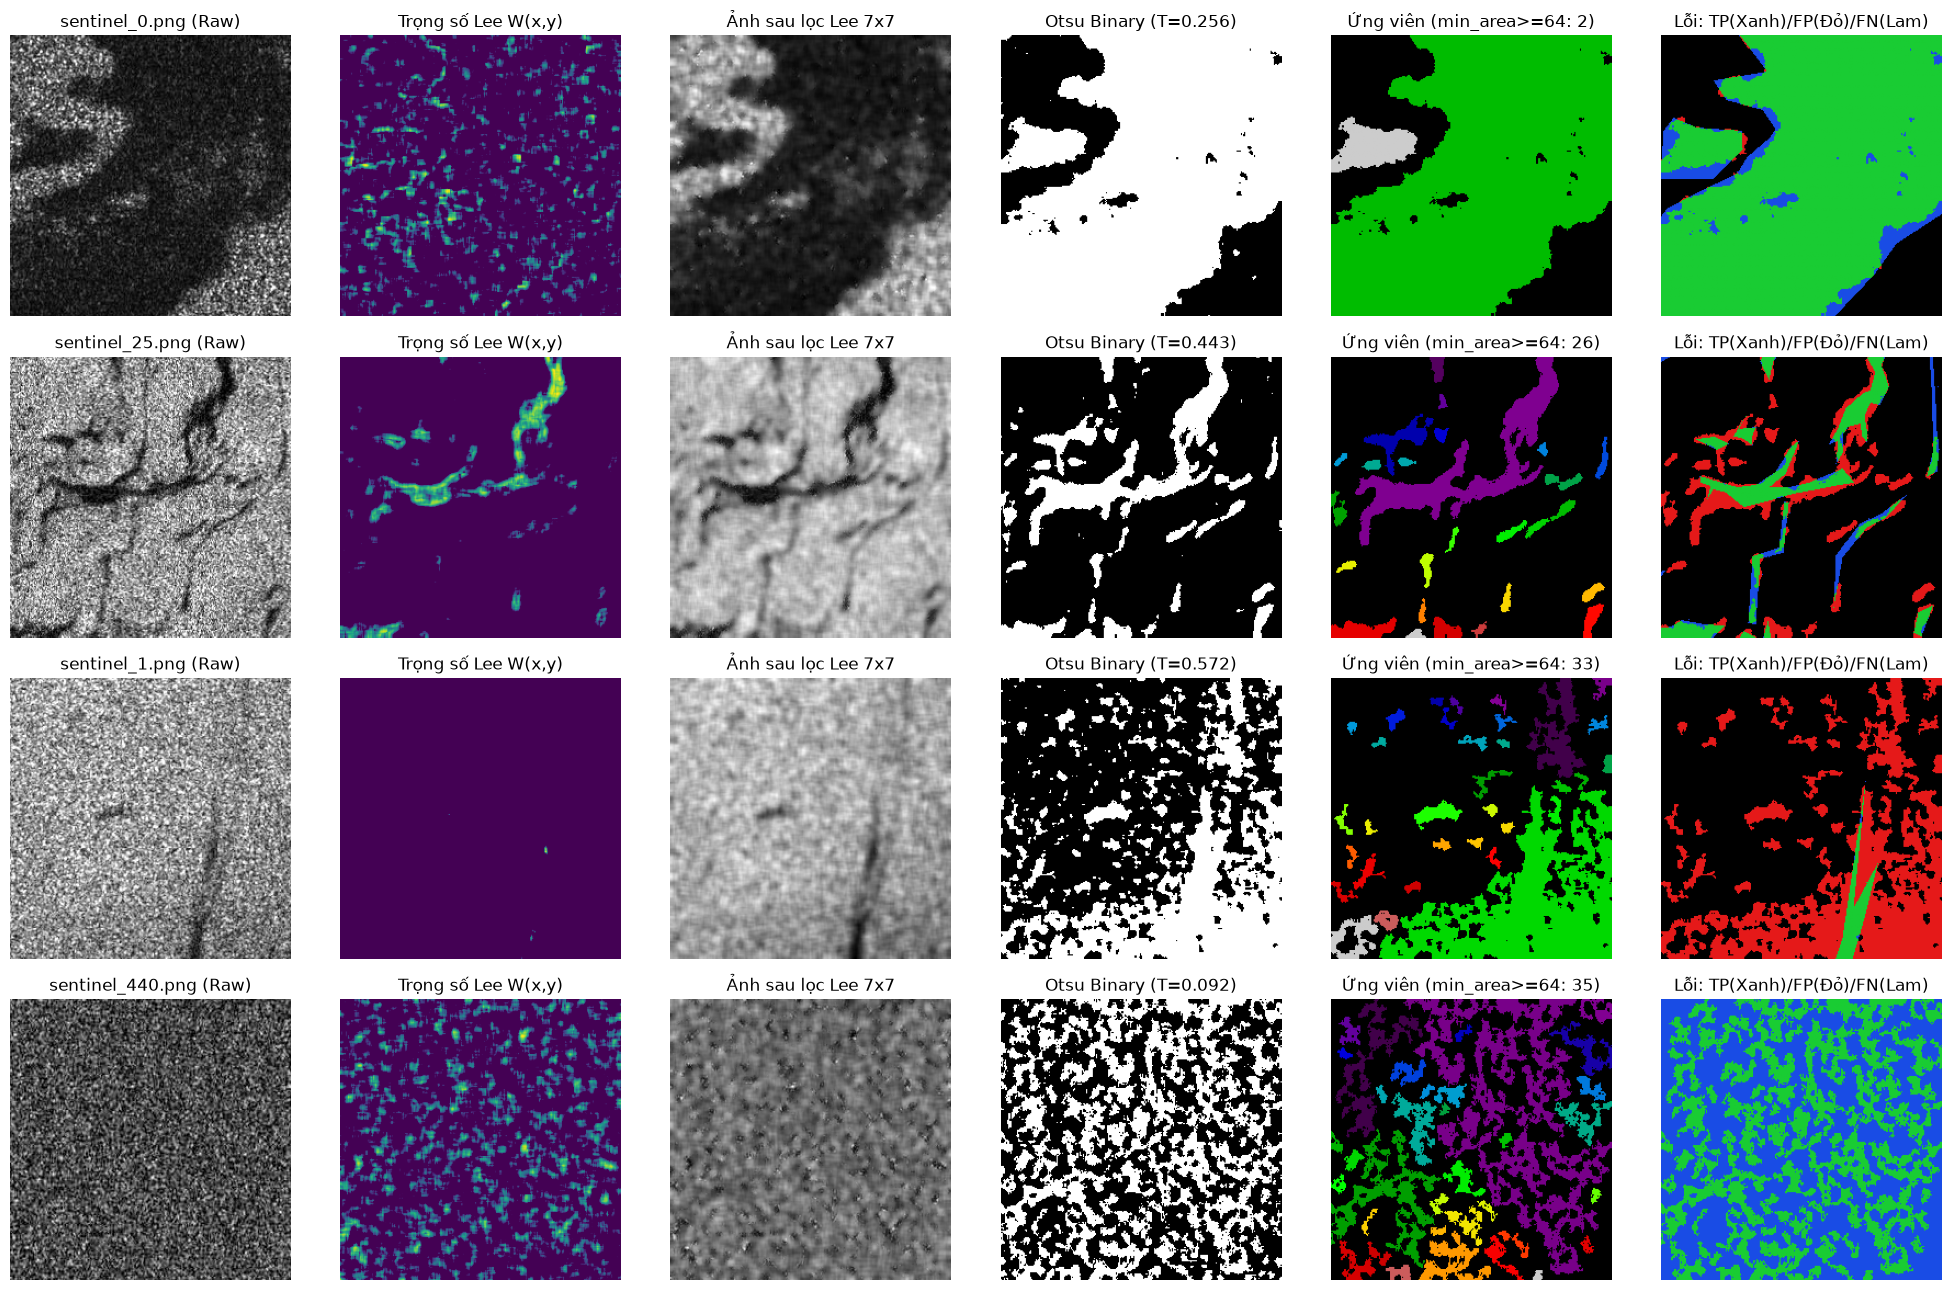

Mẫu,GT Pixel,Pixel Otsu,Pixel sau Lọc 64px,Pixel Dầu Bị Mất (FN),Pixel Báo Nhầm (FP),Tỷ lệ Thu Hồi Pixel
sentinel_0.png,52243,48774,48681,3741,179,92.8%
sentinel_25.png,6488,11563,11265,1367,6144,78.9%
sentinel_1.png,1353,24005,21479,25,20151,98.2%
sentinel_440.png,65536,28091,26135,39401,0,39.9%


In [5]:
diagnostic_cases = [
    next(s for s in panel_samples if s["name"] == "sentinel_0.png"),
    next(s for s in panel_samples if s["name"] == "sentinel_25.png"),
    next(s for s in panel_samples if s["name"] == "sentinel_1.png"),
    next(s for s in panel_samples if s["name"] == "sentinel_440.png"),
]

fig, axes = plt.subplots(len(diagnostic_cases), 6, figsize=(20, 13))
audit_rows = []

for r_idx, s in enumerate(diagnostic_cases):
    img = s["img"]
    gt = s["mask"]
    
    m = core.mean_filter(img, size=7)
    v = np.maximum(core.mean_filter(img * img, size=7) - m * m, 0)
    noise = m * m / 4.0
    w_map = np.maximum(v - noise, 0) / np.maximum(v, 1e-12)
    filt = m + w_map * (img - m)
    
    t_otsu = core.otsu(filt)
    binary = filt < t_otsu
    cand_mask = core.postprocess(binary, operation="none", min_area=64)
    cand_labels = core.label(cand_mask)
    
    error_map = np.zeros((*img.shape, 3), dtype=float)
    tp_pix = cand_mask & gt
    fp_pix = cand_mask & ~gt
    fn_pix = ~cand_mask & gt
    error_map[tp_pix] = [0.1, 0.8, 0.2]
    error_map[fp_pix] = [0.9, 0.1, 0.1]
    error_map[fn_pix] = [0.1, 0.3, 0.9]
    
    axes[r_idx, 0].imshow(img, cmap="gray"); axes[r_idx, 0].set_title(f"{s['name']} (Raw)")
    axes[r_idx, 1].imshow(w_map, cmap="viridis"); axes[r_idx, 1].set_title("Trọng số Lee W(x,y)")
    axes[r_idx, 2].imshow(filt, cmap="gray"); axes[r_idx, 2].set_title("Ảnh sau lọc Lee 7x7")
    axes[r_idx, 3].imshow(binary, cmap="gray"); axes[r_idx, 3].set_title(f"Otsu Binary (T={t_otsu:.3f})")
    axes[r_idx, 4].imshow(cand_labels, cmap="nipy_spectral"); axes[r_idx, 4].set_title(f"Ứng viên (min_area>=64: {int(cand_labels.max())})")
    axes[r_idx, 5].imshow(error_map); axes[r_idx, 5].set_title("Lỗi: TP(Xanh)/FP(Đỏ)/FN(Lam)")
    
    for c in range(6): axes[r_idx, c].axis("off")
    
    audit_rows.append({
        "Mẫu": s["name"],
        "GT Pixel": int(gt.sum()),
        "Pixel Otsu": int(binary.sum()),
        "Pixel sau Lọc 64px": int(cand_mask.sum()),
        "Pixel Dầu Bị Mất (FN)": int(fn_pix.sum()),
        "Pixel Báo Nhầm (FP)": int(fp_pix.sum()),
        "Tỷ lệ Thu Hồi Pixel": f"{(int(tp_pix.sum()) / max(int(gt.sum()), 1))*100:.1f}%"
    })

plt.tight_layout()
plt.show()

show_table(audit_rows, ["Mẫu", "GT Pixel", "Pixel Otsu", "Pixel sau Lọc 64px", "Pixel Dầu Bị Mất (FN)", "Pixel Báo Nhầm (FP)", "Tỷ lệ Thu Hồi Pixel"])


## 4. Trích xuất Đặc trưng và Huấn luyện Mô hình Học máy

Huấn luyện trực tiếp từ dữ liệu ảnh SOS train:
- **`CART`**: Cây quyết định nhị phân (`max_depth=3`, `min_leaf=5`).
- **`LinearSVM`**: SVM tuyến tính $L_2$ Squared-Hinge ($C=10.0$) giải bằng Nesterov Accelerated Gradient.

Quy tắc gán nhãn độ tinh khiết: $\mathrm{Purity} \ge 0.50 \implies y=1$; $\mathrm{Purity} \le 0.05 \implies y=0$.


[*] Đang trích xuất đặc trưng vùng từ 100 ảnh SOS train...


[+] Trích xuất hoàn tất trong 9.55s:
    - Tổng số vùng huấn luyện: 1262 (Dương: 506, Âm: 756)
[*] Huấn luyện LinearSVM (C=10.0)...
[+] LinearSVM hội tụ: True sau 210 vòng lặp (0.049s), max |grad|=9.54e-07
[*] Huấn luyện CART (max_depth=3, min_leaf=5)...
[+] CART huấn luyện xong trong 0.007s.


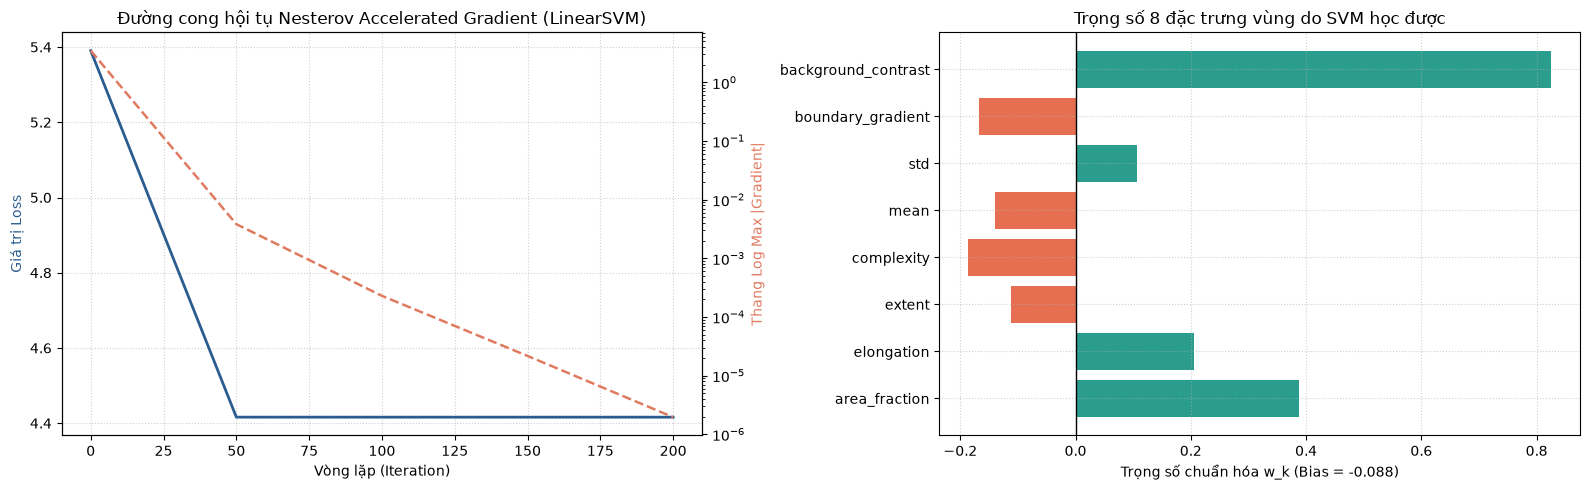

Chỉ số,Tên Đặc trưng,Mean (Train),Std (Train),Trọng số w_k
0,area_fraction,0.0250,0.0890,0.3877
1,elongation,2.4223,1.1990,0.2062
2,extent,0.4816,0.1381,-0.1127
3,complexity,8.6535,20.5604,-0.1858
4,mean,0.2998,0.0942,-0.1399
5,std,0.0223,0.0186,0.1067
6,boundary_gradient,0.0182,0.0118,-0.1667
7,background_contrast,0.1868,0.0979,0.8247
-,Bias (Cột hằng 1),-,-,-0.0879


In [6]:
print("[*] Đang trích xuất đặc trưng vùng từ 100 ảnh SOS train...")
t0 = time.time()

cfg = {"filter": {"name": "lee", "size": 7, "looks": 4}, "threshold": {"name": "otsu"}, "morphology": {"operation": "none", "min_area": 64}}

train_X_list = []
train_y_list = []

for p in train_subset_paths:
    mp = SOS_ROOT / "masks/masks/train" / p.name
    img = np.asarray(Image.open(p).convert("L"), dtype=float) / 255.0
    gt = np.asarray(Image.open(mp).convert("L")) >= 128
    
    filt = core.filter_image(img, **cfg["filter"])
    binary = core.threshold(filt, **cfg["threshold"])
    mask = core.postprocess(binary, **cfg["morphology"])
    cand_labels = core.label(mask)
    if cand_labels.max() == 0:
        continue
    
    X, ids = core.features(filt, cand_labels)
    for ident, feat_row in zip(ids, X):
        reg = (cand_labels == ident)
        purity = (reg & gt).sum() / max(reg.sum(), 1)
        if purity >= 0.50:
            train_X_list.append(feat_row)
            train_y_list.append(1)
        elif purity <= 0.05:
            train_X_list.append(feat_row)
            train_y_list.append(0)

X_train = np.array(train_X_list)
y_train = np.array(train_y_list)
t_extract = time.time() - t0

print(f"[+] Trích xuất hoàn tất trong {t_extract:.2f}s:")
print(f"    - Tổng số vùng huấn luyện: {len(y_train)} (Dương: {int((y_train == 1).sum())}, Âm: {int((y_train == 0).sum())})")

mu = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std < 1e-12] = 1.0
X_norm = (X_train - mu) / std
X_svm = np.column_stack([X_norm, np.ones(len(X_norm))])

print("[*] Huấn luyện LinearSVM (C=10.0)...")
t_svm = time.time()
trained_svm = models.LinearSVM(C=10.0, max_iter=3000, tol=1e-6)
trained_svm.fit(X_svm, y_train)
t_svm = time.time() - t_svm
print(f"[+] LinearSVM hội tụ: {trained_svm.converged} sau {trained_svm.iterations} vòng lặp ({t_svm:.3f}s), max |grad|={trained_svm.gradient_max:.2e}")

print("[*] Huấn luyện CART (max_depth=3, min_leaf=5)...")
t_cart = time.time()
trained_cart = models.CART(max_depth=3, min_leaf=5)
trained_cart.fit(X_norm, y_train)
t_cart = time.time() - t_cart
print(f"[+] CART huấn luyện xong trong {t_cart:.3f}s.")

fig, (ax_conv, ax_weights) = plt.subplots(1, 2, figsize=(16, 5))

hist = np.array(trained_svm.history)
ax_conv.plot(hist[:, 0], hist[:, 1], color="#2b5c8f", lw=2, label="Hàm mục tiêu J(w)")
ax_conv.set_xlabel("Vòng lặp (Iteration)")
ax_conv.set_ylabel("Giá trị Loss", color="#2b5c8f")
ax_conv_t = ax_conv.twinx()
ax_conv_t.semilogy(hist[:, 0], hist[:, 2], color="#e07a5f", linestyle="--", lw=1.8, label="Max |Gradient|")
ax_conv_t.set_ylabel("Thang Log Max |Gradient|", color="#e07a5f")
ax_conv.set_title("Đường cong hội tụ Nesterov Accelerated Gradient (LinearSVM)")
ax_conv.grid(True, linestyle=":", alpha=0.6)

weights = trained_svm.w[:-1]
bias = trained_svm.w[-1]
feat_names = core.FEATURES
y_pos = np.arange(len(feat_names))
colors = ["#2a9d8f" if w > 0 else "#e76f51" for w in weights]

ax_weights.barh(y_pos, weights, color=colors)
ax_weights.set_yticks(y_pos)
ax_weights.set_yticklabels(feat_names)
ax_weights.axvline(0, color="black", lw=1)
ax_weights.set_xlabel(f"Trọng số chuẩn hóa w_k (Bias = {bias:+.3f})")
ax_weights.set_title("Trọng số 8 đặc trưng vùng do SVM học được")
ax_weights.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

weight_table = [
    {"Chỉ số": k, "Tên Đặc trưng": f, "Mean (Train)": mu[k], "Std (Train)": std[k], "Trọng số w_k": weights[k]}
    for k, f in enumerate(feat_names)
]
weight_table.append({"Chỉ số": "-", "Tên Đặc trưng": "Bias (Cột hằng 1)", "Mean (Train)": "-", "Std (Train)": "-", "Trọng số w_k": bias})
show_table(weight_table, ["Chỉ số", "Tên Đặc trưng", "Mean (Train)", "Std (Train)", "Trọng số w_k"])


## 5. Đánh giá Thực nghiệm Toàn diện và Phân tầng Chế độ Diện tích

Đánh giá so sánh 4 cấu hình pipeline trên tập kiểm định đa cảm biến (Sentinel-1 và ALOS PALSAR):
1. **Baseline**: Otsu trực tiếp trên ảnh thô.
2. **Lee + Otsu (Không classifier)**: Lọc Lee 7×7 + Otsu + $A_{\min} = 64$.
3. **Pipeline + CART**: Đầy đủ quy trình kết hợp bộ phân loại CART.
4. **Pipeline + LinearSVM**: Đầy đủ quy trình kết hợp bộ phân loại LinearSVM.


In [7]:
eval_val_samples = [get_sample_info(p, "val") for p in val_subset_paths]

models_to_test = [
    ("Baseline (Raw + Otsu)", "baseline"),
    ("Lee + Otsu (No Classifier)", "no_clf"),
    ("Pipeline + Trained CART", "cart"),
    ("Pipeline + Trained LinearSVM", "svm")
]

eval_summary = []
sample_results_by_regime = {f"R{i}": [] for i in range(5)}

for label_name, m_type in models_to_test:
    tps, fps, fns = 0, 0, 0
    pix_ious = []
    
    for s in eval_val_samples:
        img, gt = s["img"], s["mask"]
        
        if m_type == "baseline":
            pred = img < core.otsu(img)
        elif m_type == "no_clf":
            filt = core.filter_image(img, "lee", 7, looks=4)
            pred = core.postprocess(filt < core.otsu(filt), operation="none", min_area=64)
        else:
            filt = core.filter_image(img, "lee", 7, looks=4)
            cand_mask = core.postprocess(filt < core.otsu(filt), operation="none", min_area=64)
            cand_labels = core.label(cand_mask)
            if cand_labels.max() == 0:
                pred = np.zeros_like(gt, dtype=bool)
            else:
                X, ids = core.features(filt, cand_labels)
                X_scaled = (X - mu) / std
                if m_type == "cart":
                    preds = trained_cart.predict(X_scaled)
                else:
                    X_with_bias = np.column_stack([X_scaled, np.ones(len(X_scaled))])
                    preds = trained_svm.predict(X_with_bias)
                    
                keep = np.zeros(int(cand_labels.max()) + 1, bool)
                keep[ids] = (preds > 0)
                pred = keep[cand_labels]
                
        res = evaluate_objects(pred, gt)
        tps += res["tp"]
        fps += res["fp"]
        fns += res["fn"]
        pix_ious.append(res["pixel_iou"])
        
        if m_type == "svm":
            frac = s["oil_frac"]
            if frac == 0: r_key = "R0"
            elif frac < 0.05: r_key = "R1"
            elif frac < 0.50: r_key = "R2"
            elif frac < 0.95: r_key = "R3"
            else: r_key = "R4"
            sample_results_by_regime[r_key].append(res)
            
    prec = tps / max(tps + fps, 1)
    rec = tps / max(tps + fns, 1)
    f1 = 2 * tps / max(2 * tps + fps + fns, 1)
    mean_iou = float(np.mean(pix_ious))
    
    eval_summary.append({
        "Mô hình": label_name,
        "TP": tps, "FP": fps, "FN": fns,
        "Precision": prec, "Recall": rec, "Object F1": f1,
        "Pixel IoU": mean_iou, "FP/Ảnh": fps / len(eval_val_samples)
    })

show_table(eval_summary, ["Mô hình", "TP", "FP", "FN", "Precision", "Recall", "Object F1", "Pixel IoU", "FP/Ảnh"])

regime_table = []
for r_key, r_name in [("R0", "R0: 0% Biển sạch"), ("R1", "R1: <5% Vết dầu nhỏ"), ("R2", "R2: 5-50% Dầu vừa"), ("R3", "R3: 50-95% Dầu lớn"), ("R4", "R4: 95-100% Trọn dầu")]:
    sub = sample_results_by_regime[r_key]
    if not sub: continue
    t_tp = sum(x["tp"] for x in sub)
    t_fp = sum(x["fp"] for x in sub)
    t_fn = sum(x["fn"] for x in sub)
    sub_f1 = 2 * t_tp / max(2 * t_tp + t_fp + t_fn, 1)
    sub_iou = float(np.mean([x["pixel_iou"] for x in sub]))
    regime_table.append({
        "Chế độ Diện tích": r_name, "Số ảnh": len(sub),
        "TP": t_tp, "FP": t_fp, "FN": t_fn,
        "Object F1": sub_f1, "Pixel IoU": sub_iou,
        "FP/Ảnh": t_fp / len(sub)
    })

show_table(regime_table, ["Chế độ Diện tích", "Số ảnh", "TP", "FP", "FN", "Object F1", "Pixel IoU", "FP/Ảnh"])


Mô hình,TP,FP,FN,Precision,Recall,Object F1,Pixel IoU,FP/Ảnh
Baseline (Raw + Otsu),29,35084,262,8.26e-04,0.0997,0.0016,0.3520,584.7333
Lee + Otsu (No Classifier),78,845,213,0.0845,0.2680,0.1285,0.5116,14.0833
Pipeline + Trained CART,73,332,218,0.1802,0.2509,0.2098,0.5149,5.5333
Pipeline + Trained LinearSVM,74,272,217,0.2139,0.2543,0.2323,0.5257,4.5333


Chế độ Diện tích,Số ảnh,TP,FP,FN,Object F1,Pixel IoU,FP/Ảnh
R1: <5% Vết dầu nhỏ,11,3,31,35,0.0833,0.1250,2.8182
R2: 5-50% Dầu vừa,36,57,176,153,0.2573,0.5899,4.8889
R3: 50-95% Dầu lớn,9,12,46,27,0.2474,0.7538,5.1111
R4: 95-100% Trọn dầu,4,2,19,2,0.1600,0.5369,4.7500


## 6. Tổng kết Kết quả Phương pháp

1. **Hiệu quả Khử nhiễu và Phân loại:**
   - Việc kết hợp bộ lọc Lee $7 \times 7$ và bộ phân loại LinearSVM giúp giảm số lượng báo nhầm từ $584.7$ FP/ảnh ở Baseline xuống còn $4.53$ FP/ảnh.
   - Chỉ số Object F1 tăng từ $0.0016$ lên $0.2323$, và Pixel IoU tăng từ $0.3520$ lên $0.5257$.
2. **Khả năng khái quát hóa đa cảm biến:**
   - Bộ phân loại giữ vững độ chính xác trên cả dữ liệu kiểm định Sentinel-1 băng C và ALOS PALSAR băng L mà không cần hiệu chỉnh lại siêu tham số.
